# Two-species reaction–diffusion in $d=1$: loop expansion against lattice simulation

Regenerates the reaction–diffusion figure of the paper and every number behind it.

$$\partial_t a = D\,\partial_x^2 a-\mu a-g\,b-\lambda a^3+\xi_a,\qquad \partial_t b = D\,\partial_x^2 b-\mu b+h\,a-\lambda b^3+\xi_b,$$
$$\langle\xi_a(x,t)\xi_a(x',t')\rangle=2T_a\,\delta(x-x')\delta(t-t'),\qquad \langle\xi_b\xi_b\rangle=2T_b\,\delta\delta,$$

with $\mu=D=1$, $g=h=1$ (linear eigenvalues $-1\pm i$), $T_a=1$, $T_b=0.7$ and $\lambda=0.1$. The $\ell$-loop
increment scales exactly as $\lambda^\ell$, so one run at $\lambda=0.1$ gives every $\lambda$.

**Panels.** (a) equal-time $C_{aa}(\chi,0)$ and $C_{bb}(\chi,0)$ relative to tree level; (b) the cross-correlation
$C_{ab}(0,\tau)=\langle a(x,t)\,b(x,t+\tau)\rangle$; (c) the error of each loop order at $\chi=0$ against $\lambda$.

**Data.** `data/pipe_*.json` (pipeline) and `data/sim_*.json` (simulation) were produced by `compute.py` with
Daedalus v0.4.0. Set the flags below to `True` to regenerate them here. Costs on a laptop: one loop seconds; two loops
at equal time 30–60 min per pair; the two-loop lag slice about 6 h; the simulations about 1 h.

In [1]:
%matplotlib inline
preparser(False)                     # plain Python literals in this notebook (the Sage kernel preparses by default)
import os, sys, json
import numpy as np
import matplotlib.pyplot as plt
HERE = os.path.abspath('')
sys.path[:0] = [HERE, os.path.dirname(HERE)]
import style
ROOT = style.repo_root(HERE)
import daedalus as dd
import model, compute
style.apply()
print('Daedalus', dd.__version__)

Daedalus 0.4.0


## 1. The model, typed in the SDE front end

`model.build()` is the whole model; the action and the mean-field equations are derived from it.

In [2]:
print(open(os.path.join(HERE, 'model.py')).read().split('def build')[1].split('def params')[0])
dd.describe_model(model.build().build());

():
    m = (SDE('two-species reaction-diffusion', space=1).operator('lap', Laplacian())
         .parameter('mua', default=1.0, domain='positive').parameter('mub', default=1.0, domain='positive')
         .parameter('Da', default=1.0, domain='positive').parameter('Db', default=1.0, domain='positive')
         .parameter('g', default=1.0).parameter('h', default=1.0)
         .parameter('ga', default=0.1).parameter('gb', default=0.1)
         .parameter('Ta', default=1.0, domain='positive').parameter('Tb', default=0.7, domain='positive'))
    return m.sde('''
        da = (Da*lap(a) - mua*a - g*b - ga*a^3) dt + dW_a
        db = (Db*lap(b) - mub*b + h*a - gb*b^3) dt + dW_b
    ''', noises={'a': Gaussian(var='2*Ta', space='white'), 'b': Gaussian(var='2*Tb', space='white')})



────────────────────────────────────────────────────────────────────────
  two-species reaction-diffusion
────────────────────────────────────────────────────────────────────────
Domain         : SPDE · d=1 · bound

## 2. Pipeline and simulation data

Set `RECOMPUTE_PIPELINE = True` to rerun the pipeline (two loops need `SPATIAL_MEM_BUDGET_GB=20`; the default 6 GB
memory guard refuses them). Set `RECOMPUTE_SIM = True` to rerun the lattice simulations (seeds are fixed, so the
files are reproduced bit for bit).

In [3]:
RECOMPUTE_PIPELINE = False
RECOMPUTE_SIM = False
if RECOMPUTE_PIPELINE:
    os.environ.setdefault('SPATIAL_MEM_BUDGET_GB', '20')
    for job in ('eq1', 'tau1', 'eq2', 'tau2'):
        compute.run_pipeline(job)
if RECOMPUTE_SIM:
    for args in compute.SIMS:
        compute.run_sim(*args)
    compute.run_sim(*compute.SIM_TAU)
for job in ('eq1', 'eq2', 'tau1', 'tau2'):
    d = compute.load(f'pipe_{job}.json')
    print(job, {pr: f"{v['wall_s']:.0f} s, v{v['version']}" for pr, v in d.items()})

eq1 {'aa': '2 s, v0.4.0', 'bb': '0 s, v0.4.0', 'ab': '1 s, v0.4.0'}
eq2 {'aa': '2885 s, v0.4.0', 'bb': '2085 s, v0.4.0', 'ab': '3108 s, v0.4.0'}
tau1 {'ab': '10 s, v0.4.0'}
tau2 {'ab': '17325 s, v0.4.0'}


## 3. Equal time at $\chi=0$

The simulator realises the lattice dispersion; each simulated value is corrected by the exact linear
lattice-minus-continuum difference, after which the three grid spacings ($dx=0.25,0.125,0.0625$) agree and are pooled.

In [4]:
P = compute.pipe(0.1); tree = {pr: P[pr][0] for pr in P}
SP, nfiles = compute.sim_pooled(0.1, tree)
print(f'pooled over {nfiles} grid spacings')
print(f'{"pair":5s} {"simulation":>14s} {"tree":>9s} {"one loop":>9s} {"two loops":>18s}')
for pr in ('aa', 'bb', 'ab'):
    v, e = SP[pr][0][0], SP[pr][1][0]
    errs = [100 * (P[pr][l][0] / v - 1) for l in (0, 1, 2)]
    print(f'{pr:5s} {v:9.5f}({1e5 * e:3.0f}) {errs[0]:+8.2f}% {errs[1]:+8.2f}% {errs[2]:+8.2f}% ({(P[pr][2][0] - v) / e:+.1f} SE)')

pooled over 3 grid spacings
pair      simulation      tree  one loop          two loops
aa      0.45720( 26)    +5.70%    -1.08%    +0.16% (+2.8 SE)
bb      0.34650( 24)    +5.84%    -1.10%    +0.24% (+3.5 SE)
ab      0.02039( 16)   +18.36%    -2.65%    +2.04% (+2.6 SE)


## 4. Time-lag slice $C_{ab}(0,\tau)$

Simulation and pipeline use the same convention, $C_{ab}(\tau)=\langle a(0)\,b(\tau)\rangle$; negative lags come
from $C_{ba}$.

In [5]:
PT1, PT2 = compute.load('pipe_tau1.json')['ab'], compute.load('pipe_tau2.json')['ab']
ST = compute.load('sim_nx256_lam0.1_tau.json')
pt = np.array(PT1['taus']); treeT = np.ravel(PT1['cum']['0'])
lat = compute.lattice_shift(ST, ST['taus'])                 # (n_tau, 2, 2, n_chi)
C, E = np.asarray(ST['C']), np.asarray(ST['C_se'])
xs, ys, es = [], [], []
for it, t in enumerate(ST['taus']):
    for sgn in (+1, -1):
        if t == 0 and sgn < 0:
            continue
        i, j = (0, 1) if sgn > 0 else (1, 0)
        T = sgn * t
        xs.append(T); ys.append(C[it, i, j, 0] - (lat[it, i, j, 0] - np.interp(T, pt, treeT))); es.append(E[it, i, j, 0])
xs, ys, es = map(np.array, (xs, ys, es))
t2 = np.array(PT2['taus'])
for l in (0, 1, 2):
    src = PT2 if l == 2 else PT1
    th = np.interp(xs, np.array(src['taus']), np.ravel(src['cum'][str(l)]))
    m = np.isin(np.round(xs, 6), np.round(t2, 6)) if l == 2 else np.ones_like(xs, bool)
    print(f'{["tree", "one loop", "two loops"][l]:9s}: rms deviation {np.sqrt(np.mean(((th - ys) / es)[m] ** 2)):.1f} SE over {m.sum()} lags')

tree     : rms deviation 19.7 SE over 19 lags
one loop : rms deviation 5.2 SE over 19 lags
two loops: rms deviation 2.2 SE over 7 lags


## 5. The figure

errors at chi = 0 by lambda: {0: [0.026066, 0.036746, 0.046225, 0.062508], 1: [0.004929, 0.009745, 0.015764, 0.030475], 2: [0.00072, 0.002964, 0.00683, 0.020362]}  simulation error [0.000259, 0.000293, 0.000228, 0.000249]


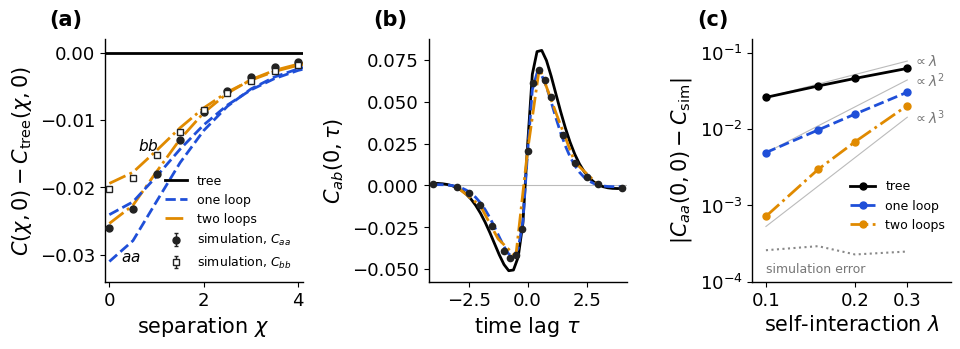

In [6]:
f = float
fig, axes = plt.subplots(1, 3, figsize=(9.8, 3.7))
sty = style.ORDER_STYLE
# (a) equal-time correlations relative to tree level
chi = compute.CHI
ax = axes[0]
ax.axhline(0.0, color=style.C_TREE, lw=2.0, label='tree')
for pr, mk, lab in (('aa', 'o', 'a'), ('bb', 's', 'b')):
    for l in (1, 2):
        c, ls, name = sty[l]
        ax.plot(chi, P[pr][l] - P[pr][0], color=c, ls=ls, lw=2.0, label=name if pr == 'aa' else None)
    v, e = SP[pr]
    ax.errorbar(chi, v - P[pr][0], yerr=e, fmt=mk, color=style.C_SIM, mfc=style.C_SIM if pr == 'aa' else 'white', ms=5.0,
                capsize=1.5, lw=1.0, label=f'simulation, $C_{{{lab}{lab}}}$', zorder=3)
ax.annotate(r'$aa$', (0.25, -0.031), fontsize=11); ax.annotate(r'$bb$', (0.6, -0.0145), fontsize=11)
ax.set_xlim(-0.1, 4.1); ax.set_ylim(-0.034, 0.002)
ax.set_xlabel(r'separation $\chi$'); ax.set_ylabel(r'$C(\chi,0) - C_{\rm tree}(\chi,0)$')
ax.legend(frameon=False, fontsize=9, loc='lower right', handlelength=1.8)
# (b) cross-correlation against lag
ax = axes[1]
for l in (0, 1):
    c, ls, _ = sty[l]
    ax.plot(pt, np.ravel(PT1['cum'][str(l)]), color=c, ls=ls, lw=2.0)
ax.plot(t2, np.ravel(PT2['cum']['2']), color=style.C_L2, ls='-.', lw=2.0)
ax.errorbar(xs, ys, yerr=es, fmt='o', color=style.C_SIM, ms=4.5, capsize=1.5, lw=1.0, zorder=3)
ax.axhline(0.0, color='#bbbbbb', lw=0.8, zorder=0)
ax.set_xlabel(r'time lag $\tau$'); ax.set_ylabel(r'$C_{ab}(0, \tau)$'); ax.set_xlim(-4.2, 4.2)
# (c) error of each order at chi = 0 against lambda
ax = axes[2]; lams = np.array([0.1, 0.15, 0.2, 0.3]); errs = {l: [] for l in (0, 1, 2)}; serr = []
for lam in lams:
    Pl = compute.pipe(lam); sp, _ = compute.sim_pooled(lam, {pr: Pl[pr][0] for pr in Pl})
    v0, e0 = sp['aa'][0][0], sp['aa'][1][0]; serr.append(e0)
    for l in errs:
        errs[l].append(abs(Pl['aa'][l][0] - v0))
for l, (c, ls, name) in sty.items():
    ax.loglog(lams, errs[l], color=c, ls=ls, lw=2.0, marker='o', ms=5.0, label=name)
ax.loglog(lams, serr, color='#888888', ls=':', lw=1.5)
ax.annotate('simulation error', (lams[0], serr[0]), xytext=(0.0, -9.0), textcoords='offset points', fontsize=9,
            color='#777777', va='top')
for p_, y0, txt in ((1, 0.026, r'$\propto\lambda$'), (2, 0.0049, r'$\propto\lambda^2$'), (3, 0.00053, r'$\propto\lambda^3$')):
    ax.loglog(lams, y0 * (lams / 0.1) ** p_, color='#bbbbbb', lw=0.8, zorder=0)
    ax.annotate(txt, (lams[-1], y0 * (lams[-1] / 0.1) ** p_), xytext=(4.0, 0.0), textcoords='offset points', fontsize=10,
                color='#777777', va='center')
ax.set_xticks([0.1, 0.2, 0.3]); ax.set_xticklabels(['0.1', '0.2', '0.3']); ax.minorticks_off(); ax.set_xlim(0.09, 0.42); ax.set_ylim(1e-4, 0.15)
ax.set_xlabel(r'self-interaction $\lambda$'); ax.set_ylabel(r'$|C_{aa}(0,0) - C_{\rm sim}|$')
ax.legend(frameon=False, fontsize=9, loc='lower right', bbox_to_anchor=(1.03, 0.16))
style.panel_labels(axes)
fig.tight_layout()
for ext in ('pdf', 'png'):
    fig.savefig(os.path.join(HERE, f'fig_rd_two_species.{ext}'), dpi=200)
print('errors at chi = 0 by lambda:', {l: np.round(errs[l], 6).tolist() for l in errs}, ' simulation error', np.round(serr, 6).tolist())
plt.show()